# Phase 1 Feature Importance

# Import Libraries

In [1]:
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

# Load Saved Models

In [2]:
root = Path.cwd().resolve()
if not (root / 'data').is_dir():
    root = root.parents[1]
data_dir = root / 'data' / 'GeneratedOutput'
rf_path = data_dir / '03.ModelTraining' / 'random_forest_model.joblib'
xgb_path = data_dir / '03.ModelTraining' / 'xgboost_model.json'
metadata_path = data_dir / '02.Preprocessing&FeatureSelection' / 'preprocessing_metadata.json'
missing = [str(path) for path in (rf_path, xgb_path, metadata_path) if not path.is_file()]
if missing:
    raise FileNotFoundError('Required feature-importance artifacts are missing:\n' + '\n'.join(missing))
features = json.loads(metadata_path.read_text())['input_features_ordered']
rf_model = joblib.load(rf_path)
xgb_model = XGBRegressor()
xgb_model.load_model(xgb_path)

# Check Feature Names

In [3]:
assert list(rf_model.feature_names_in_) == features, 'Random Forest feature names differ from metadata'
assert xgb_model.get_booster().feature_names == features, 'XGBoost feature names differ from metadata'
assert len(rf_model.feature_importances_) == len(features)
assert len(xgb_model.feature_importances_) == len(features)
print(f'Both models use the same {len(features)} recorded features.')

Both models use the same 38 recorded features.


# Plot Feature Importance

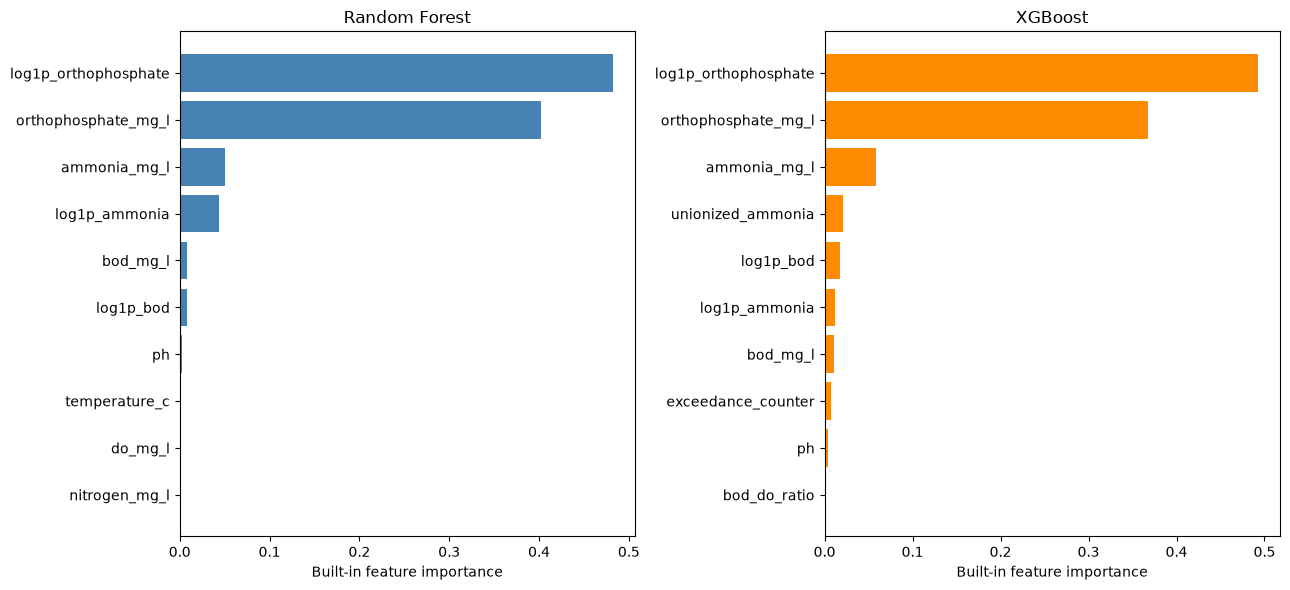

Importance scales differ between models; compare rankings within each chart.


In [4]:
importance = pd.DataFrame({'feature': features, 'Random Forest': rf_model.feature_importances_, 'XGBoost': xgb_model.feature_importances_})
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, model in zip(axes, ['Random Forest', 'XGBoost']):
    top = importance.nlargest(10, model).sort_values(model)
    ax.barh(top['feature'], top[model], color='steelblue' if model == 'Random Forest' else 'darkorange')
    ax.set_title(model)
    ax.set_xlabel('Built-in feature importance')
fig.tight_layout()
output_dir = data_dir / '04.ModelEvaluation'
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(output_dir / 'feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()
print('Importance scales differ between models; compare rankings within each chart.')